# H14 普通分钟可推导与逐笔明细特征对照

## 已执行结果索引

27次新拟合与27组旧模型恢复已完成。下表为传统GBDT的日期等权Precision@50，单位为%。
每格为“验证27日 / 评估17日”；完整对照含三模型、三期限与两段历史。

| 输入组 | T+1：验证 / 评估 | T+3：验证 / 评估 | T+5：验证 / 评估 |
| --- | ---: | ---: | ---: |
| D：昨日日频7列 | 32.88 / 39.89 | 22.56 / 29.21 | 17.70 / 25.88 |
| B：普通分钟25列 | 51.99 / 55.37 | 33.52 / 32.14 | 26.71 / 27.58 |
| L：逐笔明细20列 | 42.15 / 48.18 | 25.08 / 24.03 | 18.09 / 20.94 |
| D+B：32列 | 49.14 / 55.13 | 32.73 / 33.24 | 27.17 / 30.87 |
| D+L：27列 | 40.23 / 46.47 | 29.15 / 28.27 | 22.40 / 26.35 |
| D+B+L：52列 | 49.18 / 54.89 | 30.72 / 30.55 | 22.80 / 28.03 |
| 同池随机期望 | 9.92 / 9.93 | 9.91 / 9.93 | 9.87 / 9.92 |

相同日频下，D+B减D+L的日均配对差（百分点）：

| 模型 | T+1：验证 / 评估 | T+3：验证 / 评估 | T+5：验证 / 评估 |
| --- | ---: | ---: | ---: |
| 传统GBDT | +8.91 / +8.66 | +3.58 / +4.97 | +4.78 / +4.52 |
| HistGBDT | +8.08 / +6.59 | +5.05 / +5.34 | +3.39 / +4.52 |
| 逻辑回归 | -3.92 / -2.65 | -0.55 / +0.50 | +2.18 / +0.31 |

[完整18行对照](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/信息分组完整对照_命中率百分比.csv)、[288行配对差和区间](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/全部配对差_百分点.csv)、[52列分组明细](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/特征分组明细.csv)。
本轮结论和下一步由[卷宗H14](README.md#h14)维护。下方保留协议、分组依据、计算输出和图表；这些历史日期已用于此前研究，不能称为独立前向确认。

证据说明索引：1. 冻结与信息分组；2. 共同样本与锚点恢复；3. 固定模型拟合；4. 名单与指标；5. 配对差及覆盖；6. 图表与结束核验。

研究假设、判断及后续工作由[卷宗H14](README.md#h14)维护；本Notebook只保存执行定义和计算事实。

冻结方案：[protocol.json](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/protocol.json)，SHA-256 `87a047f8f7b25624443063c783b2267d752f611f14e7506cfcded9a3f79121cb`。主对照是相同昨日日频下，普通分钟组减逐笔明细组；独立组用于检查日频是否掩盖差异。

| 组 | 数据与维数 | 执行 |
| --- | --- | --- |
| D | 截至P可用的日频7列 | H13模型恢复 |
| B | T14:30普通分钟可推导25列 | 新拟合 |
| L | T14:30需逐笔明细20列 | 新拟合 |
| D+B | 32列 | H13模型恢复 |
| D+L | 27列 | 新拟合 |
| D+B+L | 52列 | H13模型恢复 |

B为5/15/30/60分钟和开盘至14:30五窗口的端点分钟VWAP收益、振幅、金额、数量百分位与观测分钟比例；L为同窗口笔数、笔均金额和tick-rule有符号量/额比百分位。D、B、L列互不重叠，但L比率和均值仍含价格/量/额信息，不能当作统计独立的数据源。

全部组共用原102日507,397行训练样本、日期权重、27日验证和17日评估；T+1/3/5是终点日最高价相对T日14:31–14:36 VWAP的收益排名，非持有期累计最高价。Top50在全候选池上先选，再处理未知标签；日均命中率为可评估名单的Precision@50，同时保留固定50分母边界。

本轮没有获取实际普通分钟API。B来自H13冻结分钟投影；Tushare OHLCVA字段足以表达其价格量额，但分钟边界、零成交/缺失记录及全市场横截面仍需同口径。日频排名、资格池和标签仍保留原L2数据域的lineage，不是整条链路摆脱L2的验证。历史44日已查看，不构成新的独立确认。

复现：使用[冻结源码](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/runtime-source/)、[输入清单](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/input-manifest.json)和协议指定的锁定环境，在新的隔离输出目录复制冻结输入后运行。设 `SUBSCRIPTION_INFORMATION_EVIDENCE` 为该目录，`PYTHONPATH` 指向对应 `runtime-source`。执行器见[execute_notebook.py](/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw/execute_notebook.py)。完整分钟重建证据在[H13归档](/home/wsw/app/research-evidence/subscription-intraday-ablation-2026-10-08-8phsjgoc/intraday_information_ablation.html)。27次新拟合只执行一次，保留全部正负结果、失败和不收敛。


## 1. 冻结输入与列分组

复核363份输入、169份源码、环境版本与已冻结的146日特征；本轮不重新计算特征。

In [1]:
from pathlib import Path
from datetime import datetime, date, time
from zoneinfo import ZoneInfo
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import time as wall_time
import traceback
import warnings

import joblib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from joblib import Parallel, delayed
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, brier_score_loss
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

import src
from src.training.top_selection import select_top_symbols, evaluate_top_selection
from src.utils.datetime_utils import DateTimeUtils
from src.utils.filesystem import FileSystem
from src.utils.parquet_writer import write_parquet_atomic

evidence = Path(os.environ.get('SUBSCRIPTION_INFORMATION_EVIDENCE','/home/wsw/app/research-evidence/subscription-information-groups-2026-10-09-t1_uzskw'))
assert Path(src.__file__).resolve() == (evidence/'runtime-source/src/__init__.py').resolve()
protocol_bytes = (evidence/'protocol.json').read_bytes()
protocol_hash = hashlib.sha256(protocol_bytes).hexdigest()
assert protocol_hash == '87a047f8f7b25624443063c783b2267d752f611f14e7506cfcded9a3f79121cb'
protocol = json.loads(protocol_bytes)
manifest = json.loads((evidence/'input-manifest.json').read_text())
assert hashlib.sha256((evidence/'input-manifest.json').read_bytes()).hexdigest() == protocol['input_manifest_sha256']
for entry in manifest:
    with (evidence/entry['path']).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest() == entry['sha256'], entry['path']
source_manifest = json.loads((evidence/'anchor-source-manifest.json').read_text())
assert hashlib.sha256((evidence/'anchor-source-manifest.json').read_bytes()).hexdigest() == protocol['source_manifest_sha256']
for path, entry in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/path).read_bytes()).hexdigest() == entry['sha256']
assert hashlib.sha256((evidence/'environment/uv.lock').read_bytes()).hexdigest() == protocol['environment_lock_sha256']
environment = json.loads((evidence/'environment.json').read_text())
assert platform.python_version() == environment['python']
for name,version in environment['packages'].items():
    assert importlib.metadata.version(name) == version
for folder in ['features','predictions','models','runs','figures','joblib-temp']:
    (evidence/folder).mkdir(exist_ok=True)
keys = ['symbol','trade_date','decision_ts_utc']
stage_by_date = {day:stage for stage,days in protocol['stages'].items() for day in days}
required_dates = sorted(set(protocol['common_train_dates']+protocol['prediction_dates']))
print({'input_files':len(manifest),'source_files':len(source_manifest),'minute_days':len(required_dates),'protocol_sha256':protocol_hash})
parent_protocol = json.loads((evidence/'parent-protocol.json').read_text())
assert hashlib.sha256((evidence/'parent-final-artifact-manifest.json').read_bytes()).hexdigest()==protocol['parent_artifact_manifest_sha256']
daily_columns=protocol['daily_columns']
ordinary_columns=protocol['ordinary_columns']
detail_columns=protocol['detail_columns']
assert list(map(len,protocol['features'].values()))==[7,25,20,32,27,52]
assert not set(daily_columns)&set(ordinary_columns) and not set(daily_columns)&set(detail_columns) and not set(ordinary_columns)&set(detail_columns)
assert set(daily_columns+ordinary_columns+detail_columns)==set(protocol['features']['full52'])
assert protocol['features']['ordinary25']==parent_protocol['ordinary_columns']
assert set(protocol['features']['detail20'])==set(parent_protocol['activity_columns']+parent_protocol['direction_columns'])
assert protocol['features']['daily_detail27']==[column for column in parent_protocol['features']['full52'] if column not in ordinary_columns]
for group in protocol['anchor_groups']:
    assert protocol['features'][group]==parent_protocol['features'][group]
feature_entries=[entry for entry in manifest if entry['path'].startswith('features/')]
assert len(feature_entries)==len(required_dates)==146
assert {Path(entry['path']).stem for entry in feature_entries}==set(required_dates)
print({'feature_blocks':{'daily':len(daily_columns),'ordinary':len(ordinary_columns),'trade_detail':len(detail_columns)},'frozen_H13_feature_days':len(feature_entries),'groups':{k:len(v) for k,v in protocol['features'].items()}})


{'input_files': 363, 'source_files': 169, 'minute_days': 146, 'protocol_sha256': '87a047f8f7b25624443063c783b2267d752f611f14e7506cfcded9a3f79121cb'}
{'feature_blocks': {'daily': 7, 'ordinary': 25, 'trade_detail': 20}, 'frozen_H13_feature_days': 146, 'groups': {'daily7': 7, 'ordinary25': 25, 'detail20': 20, 'price_volume32': 32, 'daily_detail27': 27, 'full52': 52}}


## 2. 共同训练行、标签与27组锚点

核对键、权重、标签成熟、缺失保留，重新加载锚点模型精确恢复全部分数。

In [2]:
files = sorted((evidence/'inputs/fixed/features/previous_day_daily_l2/v1').glob('trade_date=*/data.parquet'))
legacy_features = pd.concat([pd.read_parquet(path) for path in files],ignore_index=True)
labels = {h:pd.read_parquet(evidence/f'labels/t{h}.parquet') for h in protocol['horizons']}
for frame in labels.values():
    assert frame[keys].equals(legacy_features[keys]) and not frame.duplicated(keys).any()
fit_table = pd.read_parquet(evidence/'anchor-models/fit-keys.parquet')
mask = legacy_features.trade_date.isin(protocol['common_train_dates'])
for h in protocol['horizons']:
    mask &= labels[h].y_event.notna()
assert legacy_features.loc[mask,keys].reset_index(drop=True).equals(fit_table[keys])
fit_key_hash = hashlib.sha256(pd.util.hash_pandas_object(fit_table[keys],index=True).to_numpy().tobytes()).hexdigest()
assert fit_key_hash==protocol['legacy_fit_key_sha256'] and len(fit_table)==507397
weights = fit_table.weight.to_numpy(copy=True)
counts = fit_table.groupby('trade_date').symbol.transform('size').to_numpy(dtype=float)
expected_weights = 1/counts
expected_weights /= expected_weights.mean()
np.testing.assert_array_equal(weights,expected_weights)
first_decision = DateTimeUtils.local_time_to_utc_epoch_us(time(9),date.fromisoformat(protocol['prediction_dates'][0]))
for h in protocol['horizons']:
    np.testing.assert_array_equal(fit_table[f'y_t{h}'].to_numpy(),labels[h].loc[mask,'y_event'].to_numpy())
    assert labels[h].loc[mask,'label_ready_ts'].lt(first_decision).all()
    changed = labels[h].y_event.copy()
    changed.loc[~legacy_features.trade_date.isin(protocol['common_train_dates'])]=np.nan
    np.testing.assert_array_equal(changed.loc[mask],fit_table[f'y_t{h}'])
current = pd.concat([pd.read_parquet(evidence/'features'/f'{day}.parquet') for day in required_dates],ignore_index=True)
features = legacy_features.loc[legacy_features.trade_date.isin(required_dates)].rename(columns={'decision_ts_utc':'baseline_decision_ts_utc'}).copy()
features['decision_ts_utc'] = features.trade_date.map({day:DateTimeUtils.local_time_to_utc_epoch_us(time(14,30),date.fromisoformat(day)) for day in required_dates})
features = features.merge(current,on=keys,how='left',validate='one_to_one',sort=False,indicator='current_presence')
features['symbol'] = features.symbol.astype(legacy_features.symbol.dtype)
assert features[['symbol','trade_date','baseline_decision_ts_utc']].rename(columns={'baseline_decision_ts_utc':'decision_ts_utc'}).equals(legacy_features.loc[legacy_features.trade_date.isin(required_dates),keys].reset_index(drop=True))
train = fit_table[keys].rename(columns={'decision_ts_utc':'baseline_decision_ts_utc'}).merge(features,on=['symbol','trade_date','baseline_decision_ts_utc'],how='left',validate='one_to_one',sort=False)
evaluation = features.loc[features.trade_date.isin(protocol['prediction_dates'])].reset_index(drop=True)
assert len(train)==507397 and len(evaluation)==219985
new_fit_hash = hashlib.sha256(pd.util.hash_pandas_object(train[keys],index=True).to_numpy().tobytes()).hexdigest()
assert new_fit_hash==protocol['current_fit_key_sha256']
np.testing.assert_array_equal(train[keys+['baseline_decision_ts_utc']].to_numpy(),pd.read_parquet(evidence/'anchor-current-fit-keys.parquet').to_numpy())
prediction_keys = evaluation[keys+['baseline_decision_ts_utc']].copy()
prediction_keys['stage'] = prediction_keys.trade_date.map(stage_by_date)
train_arrays = {group:np.ascontiguousarray(train[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
prediction_arrays = {group:np.ascontiguousarray(evaluation[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
for group in train_arrays:
    assert np.isfinite(train_arrays[group]).all() and np.isfinite(prediction_arrays[group]).all()
    assert np.min(train_arrays[group])>=0 and np.max(train_arrays[group])<=1
missing = features.groupby('trade_date').agg(pool=('symbol','size'),current_missing=('current_presence',lambda s:int(s.eq('left_only').sum())))
missing.to_csv(evidence/'pool-coverage.csv')
fit_records=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        for group in protocol['anchor_groups']:
            stem = f'{name}-t{h}-{group}'
            saved = pd.read_parquet(evidence/'anchor-predictions'/f'{stem}.parquet')
            np.testing.assert_array_equal(saved[keys].to_numpy(),prediction_keys[keys].to_numpy())
            bundle = joblib.load(evidence/'anchor-models'/f'{stem}.joblib')
            if isinstance(bundle,dict):
                assert list(bundle['columns'])==protocol['features'][group]
            with threadpool_limits(limits=1):
                scores = bundle.predict(evaluation[protocol['features'][group]].to_numpy(dtype=float)) if name=='hist_gbdt' and group=='daily7' else bundle['estimator'].predict_proba(prediction_arrays[group])[:,1]
            np.testing.assert_array_equal(scores,saved.prediction.to_numpy())
            output = prediction_keys.copy()
            output['prediction']=scores
            write_parquet_atomic(output_file=evidence/'predictions'/f'{name}-t{h}-{group}.parquet',table=pa.Table.from_pandas(output,preserve_index=False))
            fit_records.append({'model':name,'horizon':h,'group':group,'status':'reused','fit_rows':len(train),'prediction_rows':len(evaluation),'replay_exact':True,'warnings':[]})
write_parquet_atomic(output_file=evidence/'fit-keys.parquet',table=pa.Table.from_pandas(train[keys+['baseline_decision_ts_utc']],preserve_index=False))
print({'training_rows':len(train),'prediction_rows_per_output':len(evaluation),'legacy_fit_hash':fit_key_hash,'new_decision_fit_hash':new_fit_hash,'recovered_anchor_scores':27*len(evaluation),'missing_current_stock_days':int(missing.current_missing.sum())})

{'training_rows': 507397, 'prediction_rows_per_output': 219985, 'legacy_fit_hash': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'new_decision_fit_hash': '42e379aa3da42ea222bc951249e5bf1f3852a52893235368793f88518dd6a4d6', 'recovered_anchor_scores': 5939595, 'missing_current_stock_days': 235}


## 3. 三模型的27次固定拟合

传统GBDT为主，HistGBDT和逻辑回归作模型敏感性；参数、填充、随机seed与H13相同。

In [3]:
def fit_intraday_model(name,horizon,group,train_matrix,target,sample_weights,predict_matrix,output_keys,configuration,columns,root_path,legacy_hash,current_hash,protocol_digest):
    directory = root_path/'runs'/f'{name}-t{horizon}-{group}'
    directory.mkdir(exist_ok=False)
    started = wall_time.perf_counter()
    record = {'model':name,'horizon':horizon,'group':group,'status':'running','fit_rows':len(target),
              'legacy_fit_key_sha256':legacy_hash,'decision_fit_key_sha256':current_hash,
              'started_at':datetime.now(ZoneInfo('Asia/Shanghai')).isoformat()}
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,indent=2).encode())
    try:
        constructor = {'gbdt':GradientBoostingClassifier,'hist_gbdt':HistGradientBoostingClassifier,'logistic':LogisticRegression}[name]
        estimator = constructor(**configuration)
        with threadpool_limits(limits=2 if name=='hist_gbdt' else 1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            estimator.fit(train_matrix,target,sample_weight=sample_weights)
        fit_seconds = wall_time.perf_counter()-started
        converged = not any(issubclass(w.category,ConvergenceWarning) for w in caught)
        model_path = root_path/'models'/f'{name}-t{horizon}-{group}.joblib'
        joblib.dump({'estimator':estimator,'columns':columns,'fill_value':.5,'decision_time':'14:30',
                     'legacy_fit_key_sha256':legacy_hash,'decision_fit_key_sha256':current_hash,'protocol_sha256':protocol_digest},model_path)
        with threadpool_limits(limits=1):
            np.testing.assert_array_equal(estimator.classes_,[0,1])
            scores = estimator.predict_proba(predict_matrix)[:,1]
            restored = joblib.load(model_path)
            replay = restored['estimator'].predict_proba(predict_matrix)[:,1]
        np.testing.assert_array_equal(scores,replay)
        assert len(scores)==219985 and np.isfinite(scores).all() and scores.min()>=0 and scores.max()<=1
        output = output_keys.copy()
        output['prediction']=scores
        write_parquet_atomic(output_file=root_path/'predictions'/f'{name}-t{horizon}-{group}.parquet',table=pa.Table.from_pandas(output,preserve_index=False))
        record.update(status='complete' if converged else 'unconverged',fit_seconds=fit_seconds,prediction_rows=len(scores),replay_exact=True,
                      warnings=[{'category':w.category.__name__,'message':str(w.message)} for w in caught],
                      model_sha256=hashlib.sha256(model_path.read_bytes()).hexdigest())
    except Exception as error:
        record.update(status='failed',error_type=type(error).__name__,error=str(error),traceback=traceback.format_exc())
    record['total_seconds']=wall_time.perf_counter()-started
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,ensure_ascii=False,indent=2).encode())
    return record

tasks = protocol['fit_schedule']
assert len(tasks)==27 and len({tuple(task) for task in tasks})==27
new_records = Parallel(n_jobs=12,temp_folder=evidence/'joblib-temp',max_nbytes='10M')(
    delayed(fit_intraday_model)(name,h,group,train_arrays[group],fit_table[f'y_t{h}'].to_numpy(),weights,prediction_arrays[group],prediction_keys,
                               protocol['models'][name]['params'],protocol['features'][group],evidence,fit_key_hash,new_fit_hash,protocol_hash)
    for name,h,group in tasks)
fit_records.extend(new_records)
(evidence/'fit-records.json').write_text(json.dumps(fit_records,ensure_ascii=False,indent=2)+'\n')
display(pd.DataFrame(fit_records).groupby(['model','status']).size().rename('outputs').reset_index())

,model,status,outputs
0,gbdt,complete,9
1,gbdt,reused,9
2,hist_gbdt,complete,9
3,hist_gbdt,reused,9
4,logistic,complete,9
5,logistic,reused,9


## 4. Top50名单与完整指标

按分数降序及股票代码打破并列；独立核对名单、命中分子、已知分母、随机期望和锚点日指标。

In [4]:
label_days = {h:{day:group.set_index('symbol') for day,group in frame.groupby('trade_date')} for h,frame in labels.items()}
metric_rows=[]
selection_rows=[]
for record in fit_records:
    name,h,group=record['model'],record['horizon'],record['group']
    if record['status']=='failed':
        continue
    predicted = pd.read_parquet(evidence/'predictions'/f'{name}-t{h}-{group}.parquet')
    assert predicted[keys].equals(prediction_keys[keys])
    for day,frame in predicted.groupby('trade_date',sort=True):
        lab = label_days[h][day].reindex(frame.symbol)
        symbols=frame.symbol.to_numpy(dtype=str)
        scores=frame.prediction.to_numpy(dtype=float)
        chosen=select_top_symbols(symbols,scores,top_k=50)
        independent=np.lexsort((symbols,-scores))[:50]
        np.testing.assert_array_equal(chosen,independent)
        values=asdict(evaluate_top_selection(ranks=lab.y_rank_return.to_numpy(dtype=float),selected=chosen))
        selected=lab.iloc[independent]
        assert values['hits']==int(selected.y_event.eq(1).sum())
        assert values['selected_known']==int(selected.y_event.notna().sum())
        assert values['precision']==selected.y_event.mean()
        assert values['random_precision']==lab.y_event.mean()
        known=lab.y_event.notna().to_numpy()
        metric_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'fit_status':record['status'],**values,
                            'auc':roc_auc_score(lab.y_event.to_numpy()[known],scores[known]),
                            'brier':brier_score_loss(lab.y_event.to_numpy()[known],scores[known])})
        selection_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'symbols':symbols[chosen].tolist()})
metrics=pd.DataFrame(metric_rows)
selections=pd.DataFrame(selection_rows)
write_parquet_atomic(output_file=evidence/'daily-metrics.parquet',table=pa.Table.from_pandas(metrics,preserve_index=False))
write_parquet_atomic(output_file=evidence/'selections.parquet',table=pa.Table.from_pandas(selections,preserve_index=False))
anchor = pd.read_parquet(evidence/'anchor-daily-metrics.parquet')
anchor = anchor.loc[anchor.model.isin(protocol['models']) & anchor.group.isin(protocol['anchor_groups'])].set_index(['model','horizon','group','trade_date']).sort_index()
check = metrics.loc[metrics.group.isin(protocol['anchor_groups'])].set_index(['model','horizon','group','trade_date']).sort_index()
for column in ['precision','hits','selected_known','random_precision','recall','lift','auc','brier']:
    np.testing.assert_array_equal(check[column],anchor[column])
summary=metrics.groupby(['model','horizon','stage','group']).agg(days=('trade_date','size'),precision=('precision','mean'),
    hits=('hits','sum'),known=('selected_known','sum'),coverage=('selection_coverage','mean'),recall=('recall','mean'),
    lift=('lift','mean'),random_precision=('random_precision','mean'),auc=('auc','mean'),brier=('brier','mean')).reset_index()
statuses=pd.DataFrame(fit_records)[['model','horizon','group','status']]
complete_index=pd.MultiIndex.from_product([list(protocol['models']),protocol['horizons'],list(protocol['stages']),list(protocol['features'])],names=['model','horizon','stage','group'])
full_summary=summary.set_index(['model','horizon','stage','group']).reindex(complete_index).reset_index().merge(statuses,on=['model','horizon','group'],validate='many_to_one')
full_summary.to_csv(evidence/'complete-summary.csv',index=False)
display(full_summary.loc[full_summary.model.eq('gbdt')].pivot(index=['stage','group'],columns='horizon',values='precision').mul(100).round(4))

horizon                          1        3        5
stage      group                                    
evaluation daily7          39.8872  29.2053  25.8824
           daily_detail27  46.4682  28.2665  26.3529
           detail20        48.1849  24.0264  20.9412
           full52          54.8932  30.5546  28.0312
           ordinary25      55.3709  32.1417  27.5774
           price_volume32  55.1285  33.2365  30.8715
validation daily7          32.8768  22.5627  17.7037
           daily_detail27  40.2328  29.1534  22.3976
           detail20        42.1481  25.0809  18.0922
           full52          49.1791  30.7235  22.8042
           ordinary25      51.9940  33.5208  26.7060
           price_volume32  49.1398  32.7317  27.1731

## 5. 八项配对差、区间与未知标签边界

按日期配对，以5日循环区块bootstrap为主、10日为敏感性。20,000次重抽，72项家族下界；两段各≥2个百分点且单侧95%下界>0才通过名义改善判据。随机期望仅作为描述基线。

In [5]:
paired=metrics.pivot(index=['model','horizon','stage','trade_date'],columns='group',values='precision')
paired.to_csv(evidence/'paired-daily.csv')
comparisons=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        for contrast,(treatment,control) in protocol['contrasts'].items():
            records=[r for r in fit_records if r['model']==name and r['horizon']==h and r['group'] in [treatment,control]]
            usable=all(r['status'] in ['complete','reused'] for r in records)
            if any(r['status']=='failed' for r in records):
                continue
            for stage,days in protocol['stages'].items():
                frame=paired.xs((name,h,stage)).reindex(days)
                vector=(frame[treatment]-frame[control]).to_numpy()
                assert np.isfinite(vector).all() and len(vector)==len(days)
                for block in protocol['uncertainty']['block_sessions']:
                    rng=np.random.default_rng(protocol['uncertainty']['seed'])
                    starts=rng.integers(0,len(vector),size=(20000,math.ceil(len(vector)/block)))
                    positions=((starts[...,None]+np.arange(block))%len(vector)).reshape(20000,-1)[:,:len(vector)]
                    draws=vector[positions].mean(axis=1)
                    low,high,one,adjusted=np.quantile(draws,[.025,.975,.05,protocol['uncertainty']['bonferroni_quantile']])
                    comparisons.append({'model':name,'horizon':h,'contrast':contrast,'treatment':treatment,'control':control,'stage':stage,'block_sessions':block,
                                        'mean_difference':vector.mean(),'ci95_lower':low,'ci95_upper':high,'one_sided95_lower':one,'bonferroni_lower':adjusted,
                                        'converged_complete':usable,'nominal_criterion':bool(usable and vector.mean()>=.02 and one>0),
                                        'adjusted_criterion':bool(usable and vector.mean()>=.02 and adjusted>0),'wins':int((vector>0).sum()),'ties':int((vector==0).sum()),'losses':int((vector<0).sum())})
comparison=pd.DataFrame(comparisons)
comparison.to_csv(evidence/'paired-comparison.csv',index=False)
criteria=comparison.groupby(['model','horizon','contrast','block_sessions']).agg(periods=('stage','size'),both_periods_nominal=('nominal_criterion','all'),both_periods_adjusted=('adjusted_criterion','all')).reset_index()
assert criteria.periods.eq(2).all()
criteria.to_csv(evidence/'both-periods-criteria.csv',index=False)
readable=full_summary.pivot(index=['model','horizon','stage'],columns='group',values='precision').reset_index()
random_by_period=metrics.groupby(['horizon','stage']).random_precision.mean()
readable['random']=[random_by_period.loc[(h,s)] for h,s in zip(readable.horizon,readable.stage)]
readable.to_csv(evidence/'comparison-table.csv',index=False)
primary = comparison.loc[comparison.contrast.eq('ordinary_vs_detail_with_daily') & comparison.block_sessions.eq(5),
                          ['model','horizon','stage','mean_difference','ci95_lower','ci95_upper','bonferroni_lower','wins','ties','losses']].copy()
for column in ['mean_difference','ci95_lower','ci95_upper','bonferroni_lower']:
    primary[column] *= 100
display(primary.round(4))
coverage = metrics.assign(lower_precision=metrics.hits/metrics.selected,
                          upper_precision=(metrics.hits+metrics.selected-metrics.selected_known)/metrics.selected).groupby(['model','horizon','stage','group']).agg(
                              precision=('precision','mean'),lower_precision=('lower_precision','mean'),upper_precision=('upper_precision','mean'),coverage=('selection_coverage','mean')).reset_index()
coverage.to_csv(evidence/'coverage-bounds.csv',index=False)

,model,horizon,stage,mean_difference,ci95_lower,ci95_upper,bonferroni_lower,wins,ties,losses
0,gbdt,1,validation,8.9070,5.5344,12.1119,3.3241,22,1,4
2,gbdt,1,evaluation,8.6603,6.8235,10.6843,5.8824,16,0,1
32,gbdt,3,validation,3.5782,0.3491,6.0544,-1.9006,17,1,9
34,gbdt,3,evaluation,4.9700,2.4994,7.3806,1.0588,10,4,3
64,gbdt,5,validation,4.7755,2.6788,7.0355,1.6251,19,2,6
66,gbdt,5,evaluation,4.5186,2.1651,6.4970,0.7485,12,3,2
96,hist_gbdt,1,validation,8.0801,5.2653,11.1927,3.9345,21,1,5
98,hist_gbdt,1,evaluation,6.5882,3.2941,9.1765,1.4118,14,0,3
128,hist_gbdt,3,validation,5.0549,1.2770,8.1176,-1.0433,20,1,6
130,hist_gbdt,3,evaluation,5.3397,1.8824,8.3986,-0.3529,11,2,4


## 6. 结果图与结束核验

六组主模型命中率与三模型主要配对差，随后复核输入和源码未变。

{'protocol_sha256': '87a047f8f7b25624443063c783b2267d752f611f14e7506cfcded9a3f79121cb', 'base_commit': '76c25a279685b6961cda69143f542e8ec3936f51', 'legacy_fit_key_sha256': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'new_decision_fit_key_sha256': '42e379aa3da42ea222bc951249e5bf1f3852a52893235368793f88518dd6a4d6', 'input_files_unchanged': 363, 'source_files_unchanged': 169, 'feature_days': 146, 'anchor_outputs_recovered': 27, 'new_fit_outputs': 27, 'complete_outputs': 54, 'all_complete_converged': True, 'metric_days': 2376, 'predictions': 11879190, 'all_saved_scores_replay_exact': True, 'H13_feature_partitions_frozen_exact': True, 'feature_blocks_disjoint_exact_union52': True, 'all_selections_independently_recovered': True, 'anchor_metrics_exact': True, 'feature_cutoff_inherited_from_frozen_H13': True, 'mature_training_labels': True, 'min_group_stage_coverage': 0.9881481481481481, 'research_only': True}


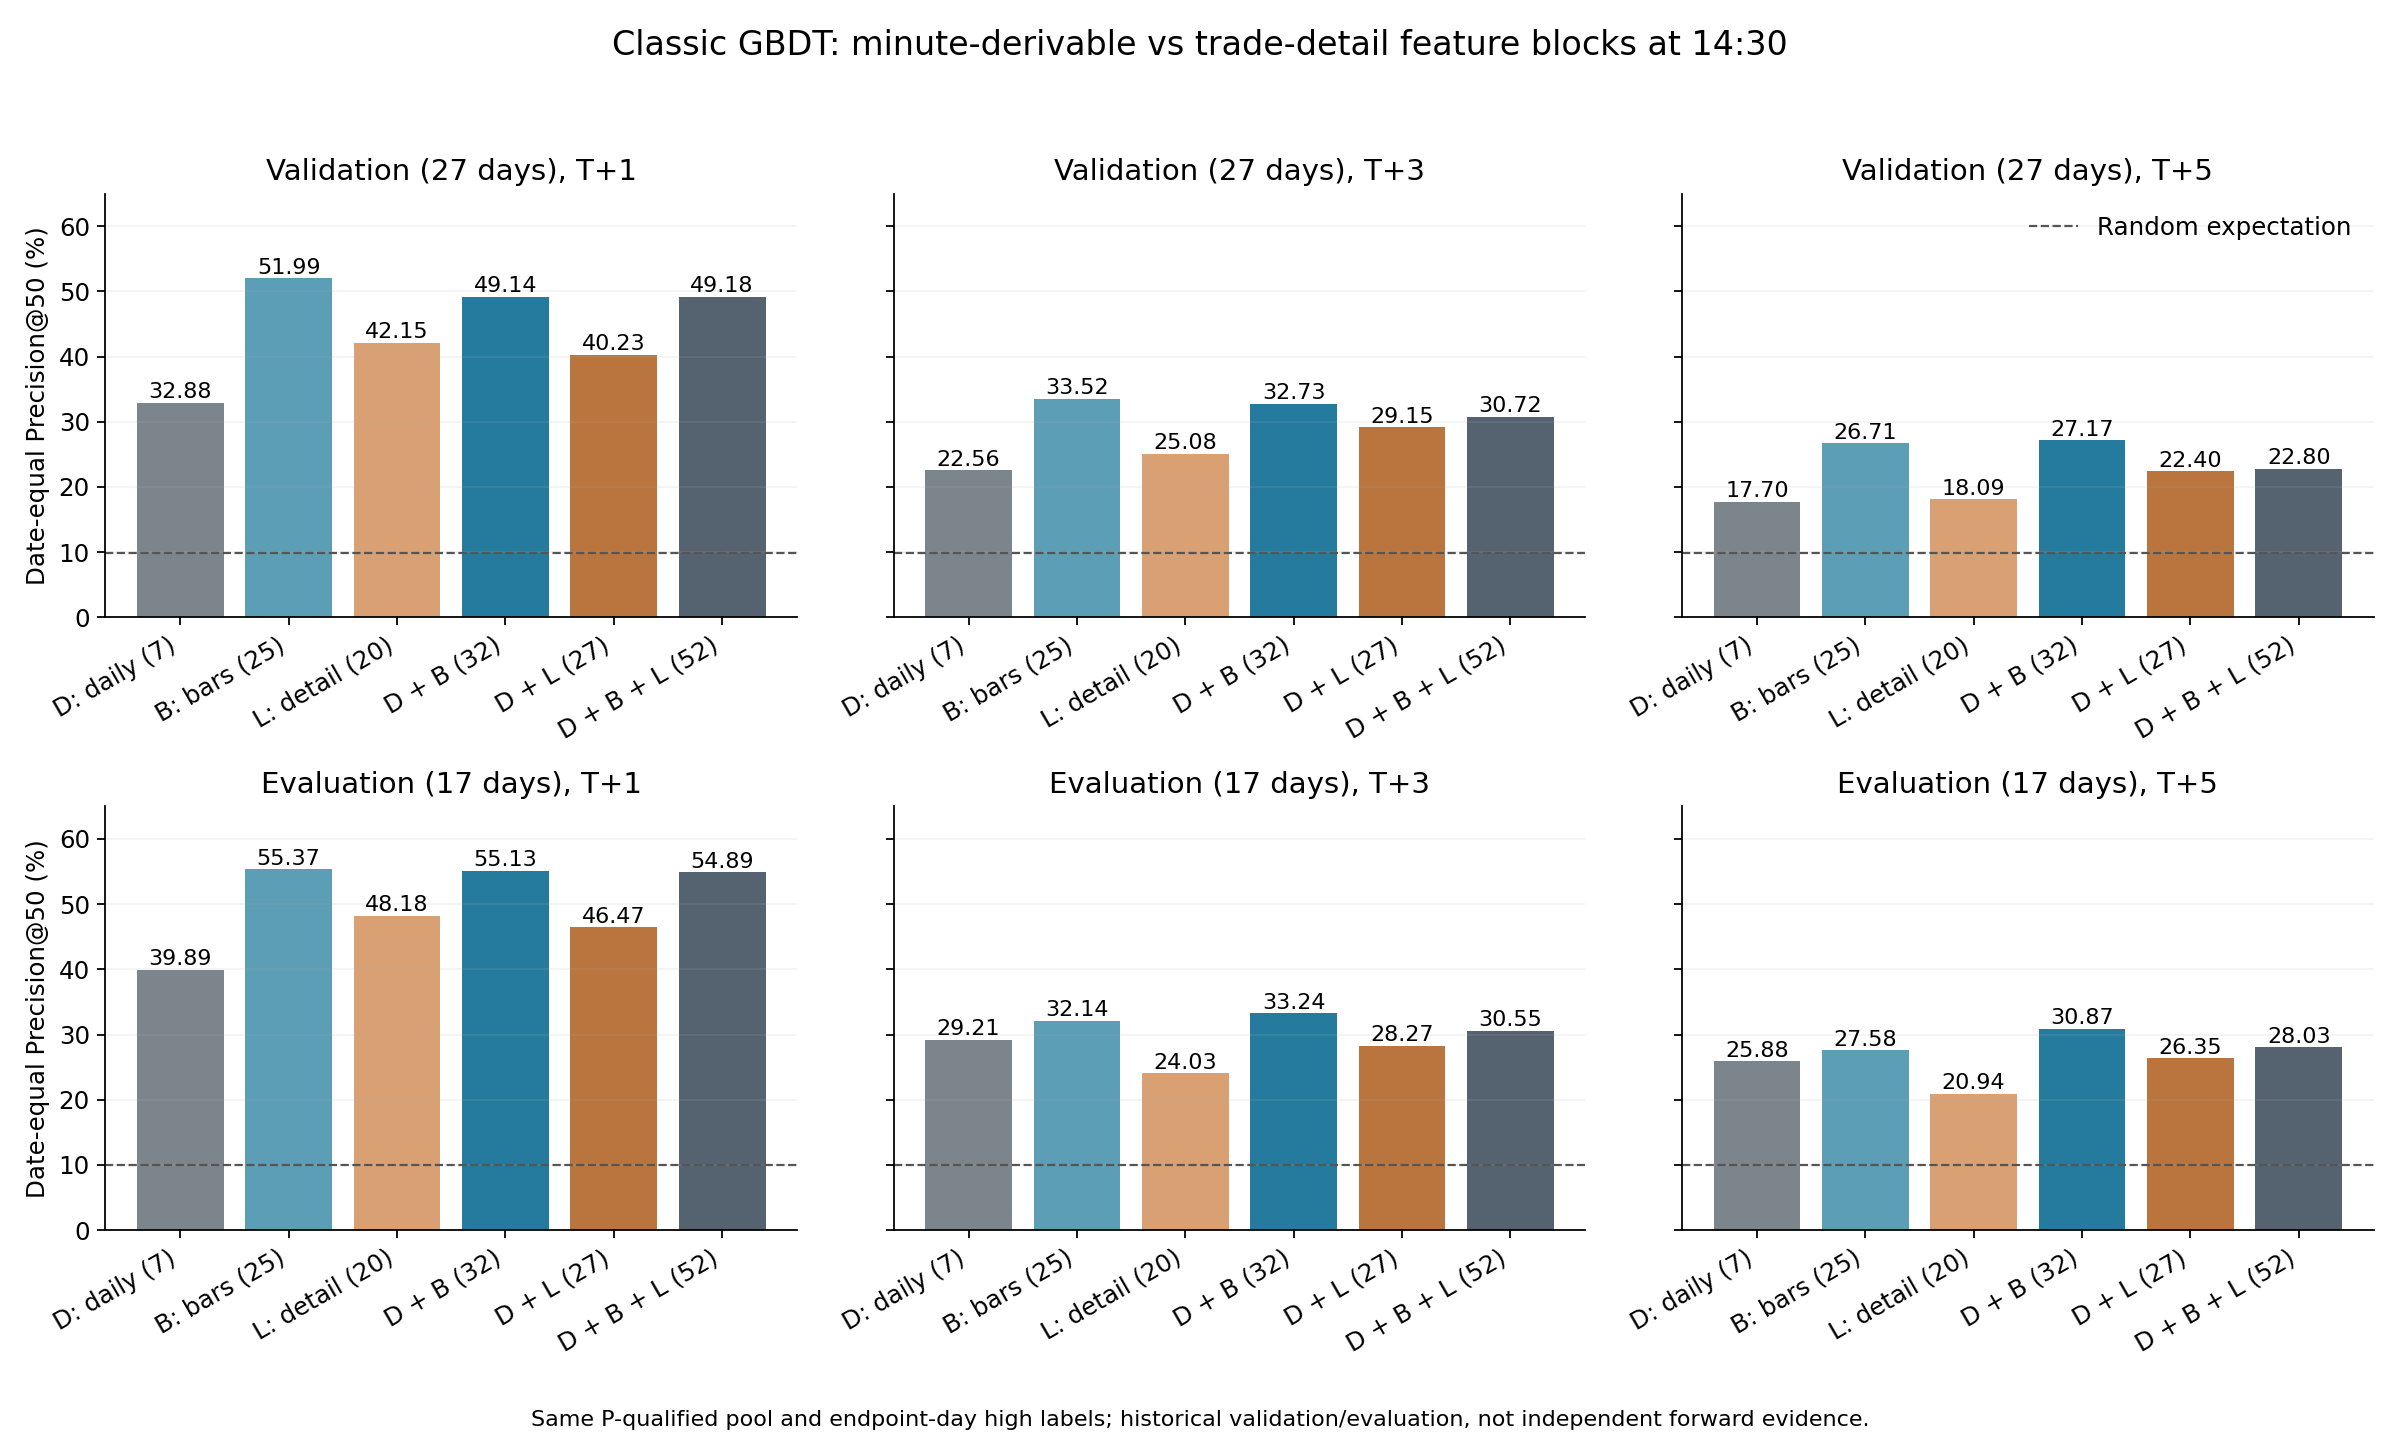

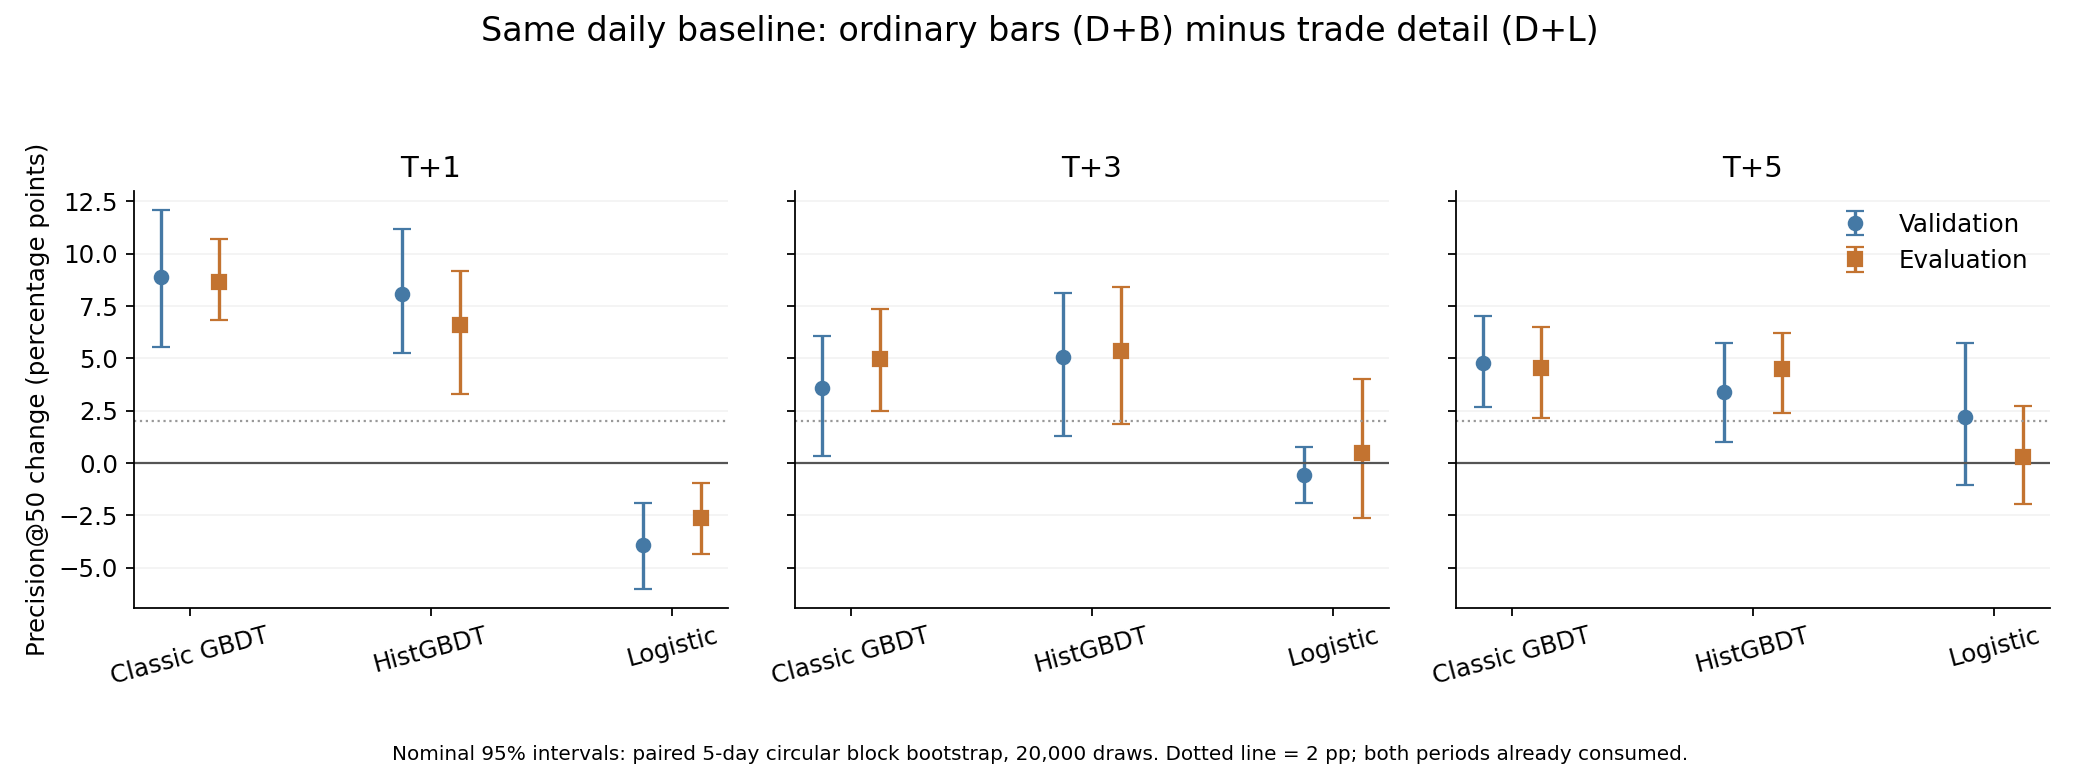

In [6]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':130,'savefig.facecolor':'white'})
group_labels={'daily7':'D: daily (7)','ordinary25':'B: bars (25)','detail20':'L: detail (20)','price_volume32':'D + B (32)','daily_detail27':'D + L (27)','full52':'D + B + L (52)'}
colors=['#7D858C','#5C9EB6','#D9A173','#247B9D','#B9753D','#556371']
fig,axes=plt.subplots(2,3,figsize=(15,9),sharey=True)
for row,stage in enumerate(protocol['stages']):
    for column,h in enumerate(protocol['horizons']):
        ax=axes[row,column]
        selected=full_summary.loc[full_summary.model.eq('gbdt')&full_summary.stage.eq(stage)&full_summary.horizon.eq(h)].set_index('group').reindex(protocol['features'])
        values=selected.precision.to_numpy()*100
        bars=ax.bar(np.arange(6),values,color=colors)
        ax.axhline(selected.random_precision.iloc[0]*100,color='#555555',ls='--',lw=1,label='Random expectation')
        for bar,value in zip(bars,values):
            if np.isfinite(value):ax.text(bar.get_x()+bar.get_width()/2,value+.7,f'{value:.2f}',ha='center',fontsize=10)
        ax.set_xticks(np.arange(6),list(group_labels.values()),rotation=30,ha='right')
        ax.set_title(f'{stage.title()} ({len(protocol["stages"][stage])} days), T+{h}')
        ax.set_ylim(0,max(55,math.ceil(full_summary.precision.max()*100/10)*10+5))
        ax.grid(axis='y',alpha=.15)
        if column==0:ax.set_ylabel('Date-equal Precision@50 (%)')
        if row==0 and column==2:ax.legend(loc='upper right',frameon=False)
fig.suptitle('Classic GBDT: minute-derivable vs trade-detail feature blocks at 14:30',fontsize=15)
fig.text(.5,.01,'Same P-qualified pool and endpoint-day high labels; historical validation/evaluation, not independent forward evidence.',ha='center',fontsize=10)
fig.tight_layout(rect=[0,.04,1,.95])
fig.savefig(evidence/'figures/gbdt-six-groups.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/gbdt-six-groups.png')))

fig,axes=plt.subplots(1,3,figsize=(13,4.8),sharey=True)
model_labels={'gbdt':'Classic GBDT','hist_gbdt':'HistGBDT','logistic':'Logistic'}
for ax,h in zip(axes,protocol['horizons']):
    for offset,stage,color,marker in [(-.12,'validation','#4579A5','o'),(.12,'evaluation','#C37330','s')]:
        selected=comparison.loc[comparison.horizon.eq(h)&comparison.contrast.eq('ordinary_vs_detail_with_daily')&comparison.block_sessions.eq(5)&comparison.stage.eq(stage)].set_index('model').reindex(protocol['models'])
        means=selected.mean_difference.to_numpy()*100
        error=np.vstack([means-selected.ci95_lower.to_numpy()*100,selected.ci95_upper.to_numpy()*100-means])
        ax.errorbar(np.arange(3)+offset,means,yerr=error,fmt=marker,color=color,capsize=4,label=stage.title())
    ax.axhline(0,color='#555555',lw=1)
    ax.axhline(2,color='#999999',lw=1,ls=':')
    ax.set_xticks(np.arange(3),list(model_labels.values()),rotation=15)
    ax.set_title(f'T+{h}')
    ax.grid(axis='y',alpha=.15)
axes[0].set_ylabel('Precision@50 change (percentage points)')
axes[-1].legend(frameon=False)
fig.suptitle('Same daily baseline: ordinary bars (D+B) minus trade detail (D+L)',fontsize=15)
fig.text(.5,.01,'Nominal 95% intervals: paired 5-day circular block bootstrap, 20,000 draws. Dotted line = 2 pp; both periods already consumed.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.07,1,.91])
fig.savefig(evidence/'figures/model-increments.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/model-increments.png')))

for entry in manifest:
    with (evidence/entry['path']).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest()==entry['sha256']
for path,entry in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/path).read_bytes()).hexdigest()==entry['sha256']
verification={'protocol_sha256':protocol_hash,'base_commit':protocol['base_commit'],'legacy_fit_key_sha256':fit_key_hash,'new_decision_fit_key_sha256':new_fit_hash,
    'input_files_unchanged':len(manifest),'source_files_unchanged':len(source_manifest),'feature_days':len(feature_entries),'anchor_outputs_recovered':27,
    'new_fit_outputs':len(new_records),'complete_outputs':sum(r['status'] in ['complete','reused'] for r in fit_records),
    'all_complete_converged':all(r['status'] in ['complete','reused'] for r in fit_records),'metric_days':len(metrics),
    'predictions':int(sum(r.get('prediction_rows',0) for r in fit_records)),'all_saved_scores_replay_exact':all(r.get('replay_exact',False) for r in fit_records),
    'H13_feature_partitions_frozen_exact':True,'feature_blocks_disjoint_exact_union52':True,'all_selections_independently_recovered':True,'anchor_metrics_exact':True,'feature_cutoff_inherited_from_frozen_H13':True,'mature_training_labels':True,
    'min_group_stage_coverage':float(full_summary.coverage.min()),'research_only':True}
(evidence/'verification.json').write_text(json.dumps(verification,indent=2)+'\n')
print(verification)